Start by loading the `tidymodels` package...

In [1]:
library('tidymodels')

── Attaching packages ───────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ──────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Use suppressPackageStartupMessages() to eliminate package startup messages


Let's work with [hotel bookings data](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md) from TidyTuesday. 

In [2]:
hotels = 
  readr::read_csv("https://tidymodels.org/start/case-study/hotels.csv", col_types = readr::cols()) |>
  mutate(across(where(is.character), as.factor)) # turns all categorical columns into factors

hotels |> head()

  hotel        lead_time stays_in_weekend_nights stays_in_week_nights adults
1 City_Hotel   217       1                       3                    2     
2 City_Hotel     2       0                       1                    2     
3 Resort_Hotel  95       2                       5                    2     
4 Resort_Hotel 143       2                       6                    2     
5 Resort_Hotel 136       1                       4                    2     
6 City_Hotel    67       2                       2                    2     
  children meal country market_segment distribution_channel ⋯
1 none     BB   DEU     Offline_TA/TO  TA/TO                ⋯
2 none     BB   PRT     Direct         Direct               ⋯
3 none     BB   GBR     Online_TA      TA/TO                ⋯
4 none     HB   ROU     Online_TA      TA/TO                ⋯
5 none     HB   PRT     Direct         Direct               ⋯
6 none     SC   GBR     Online_TA      TA/TO                ⋯
  reserved_room_type assign

Each row is a "stay" and we want to predict whether the stay included children given the other features.

We'll want to extract a bit more information from the `arrival_date` column. So, let's make a `recipe`.

In [3]:
rec = recipe(children ~ ., data = hotels) |>
    step_date(arrival_date) |>
    step_holiday(arrival_date) |>
    step_rm(arrival_date) |>
    prep()

What does this recipe do? Look at the transformed data with "juice".

In [4]:
juice(rec) |> head()

  hotel        lead_time stays_in_weekend_nights stays_in_week_nights adults
1 City_Hotel   217       1                       3                    2     
2 City_Hotel     2       0                       1                    2     
3 Resort_Hotel  95       2                       5                    2     
4 Resort_Hotel 143       2                       6                    2     
5 Resort_Hotel 136       1                       4                    2     
6 City_Hotel    67       2                       2                    2     
  meal country market_segment distribution_channel is_repeated_guest ⋯
1 BB   DEU     Offline_TA/TO  TA/TO                0                 ⋯
2 BB   PRT     Direct         Direct               0                 ⋯
3 BB   GBR     Online_TA      TA/TO                0                 ⋯
4 HB   ROU     Online_TA      TA/TO                0                 ⋯
5 HB   PRT     Direct         Direct               0                 ⋯
6 SC   GBR     Online_TA      TA/TO

Let's start with a decision tree. 

In [5]:
mod = decision_tree() |>
    set_engine('rpart') |>
    set_mode('classification')

Fit `mod` using the data from your prepped recipe. (Hint: remember `juice`).

In [6]:
mod_fit = mod |> fit(children ~ ., data = juice(rec))

Use the snippet below to visualize the tree. What is the first split?

```r
rpart.plot::rpart.plot(mod_fit$fit)
```

Warning message:
“Cannot retrieve the data used to build the model (so cannot determine roundint and is.binary for the variables).
To silence this warning:
    Call rpart.plot with roundint=FALSE,
    or rebuild the rpart model with model=TRUE.”


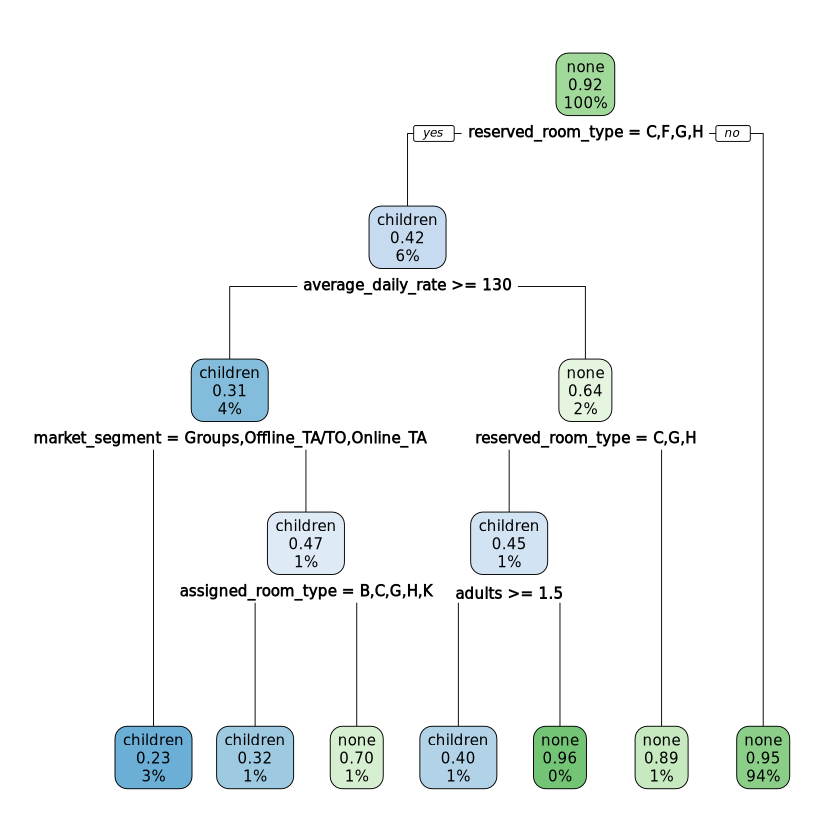

In [7]:
rpart.plot::rpart.plot(mod_fit$fit)

Now create a `random_forest` model and fit it to the transformed `hotels` data.

1. the `mode` should be "classification", and,
2. add `importance = "impurity"` to `set_engine` so we can calculate feature importances with the model.

In [8]:
rf_fit = rand_forest() |> set_engine('ranger', importance = 'impurity') |> set_mode('classification') |> fit(children ~ ., data = juice(rec))

We can plot the feature importances. Pipe your fitted model into `extract_fit_engine()` and then into `vip(num_features = 20)`.

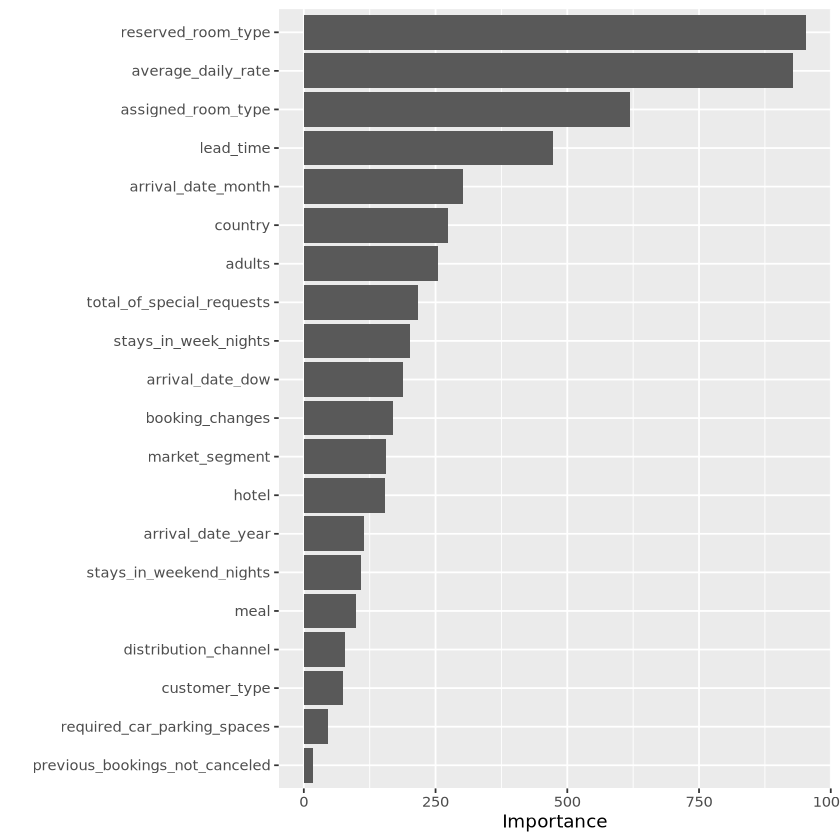

In [9]:
rf_fit |> extract_fit_engine() |> vip::vip(num_features = 20)